In [1]:
from utils230407 import *

In [2]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

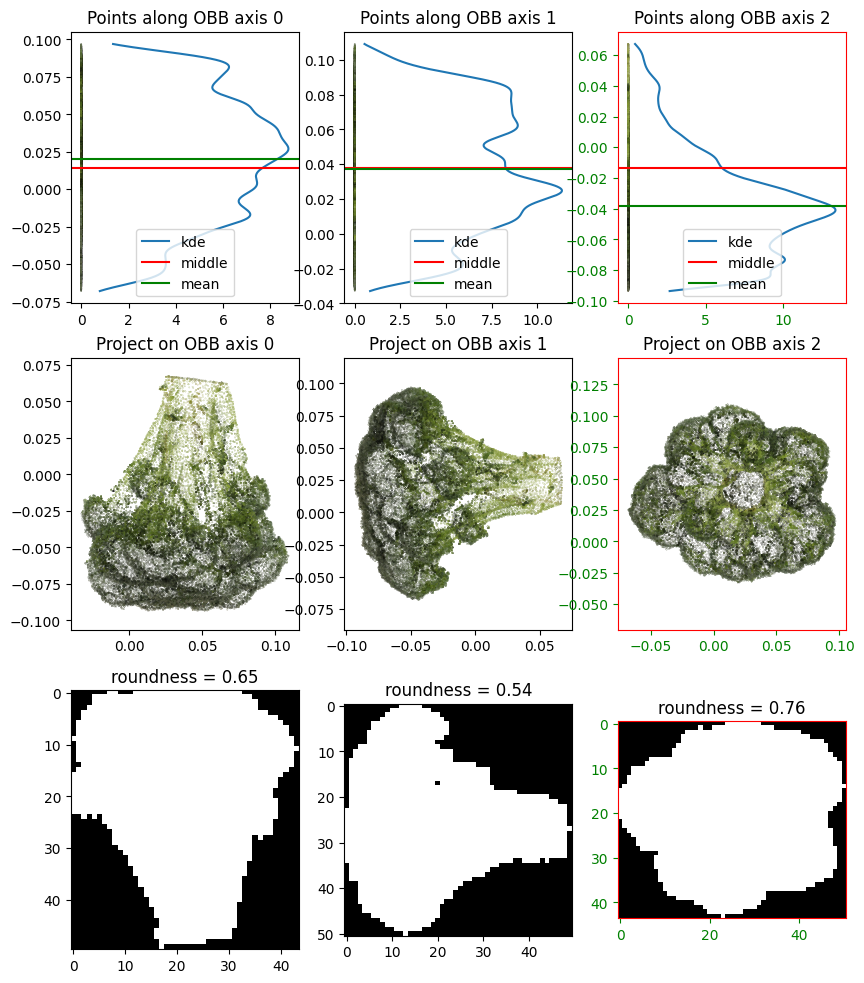

<Figure size 640x480 with 0 Axes>

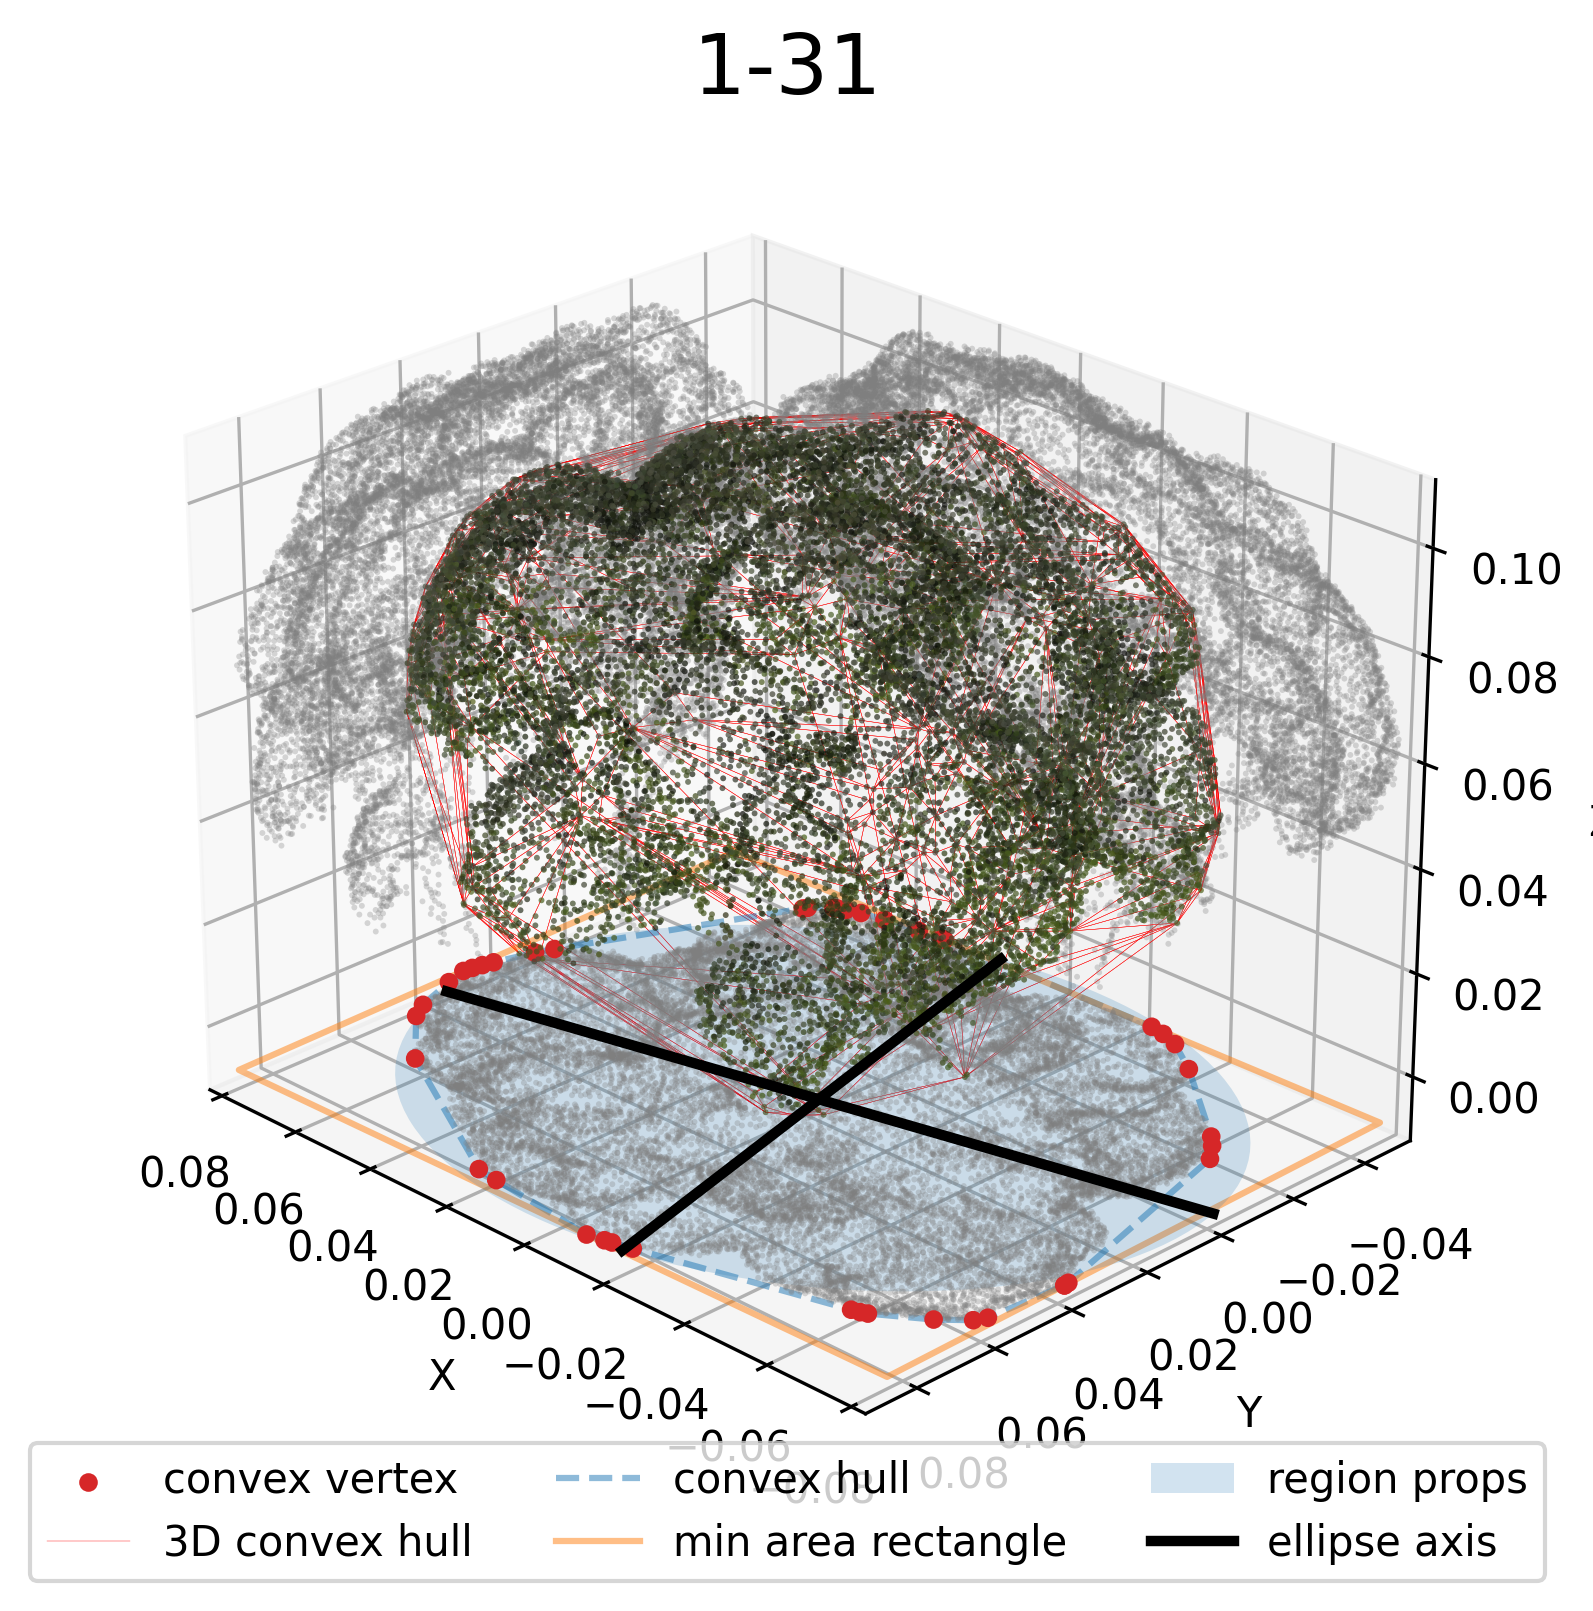

In [3]:
# bro_id = '2-31'
bro_id = '1-31'
mesh = o3d.io.read_triangle_mesh(mesh_db[bro_id],  enable_post_processing=True)
def_test_pcd = mesh2pcd(mesh)

crown_pcd, crown_colored_pcd, crown_points_index = segment_crown(def_test_pcd, 10, 0.005, show=False)

rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, show=True)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

# draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, show=True)#f"out/v220405/{broccoli_id}_rot_seg.png")

crown_traits = Broccoli(rotated_pcd.select_by_index(crown_points_index), bro_id)
draw_3d_results(crown_traits, bro_id, down_voxel_size=0.001, show=True)

In [4]:
mesh_r = copy(mesh).rotate(R)

In [5]:
cx, cy = crown_traits.centroid
cx, cy

(-0.0007354092544074875, 0.017389173463744058)

In [9]:
# cx, cy = crown_traits.rect_res[4]
# cx, cy

(0.00184136959435041, 0.018251725157585323)

find the closest and the top part

In [6]:
pts = np.asarray(rotated_pcd.points)
pts

array([[-0.01623811,  0.03105943, -0.03217931],
       [-0.01429558,  0.03213933, -0.03200542],
       [-0.0147862 ,  0.03110184, -0.03393582],
       ...,
       [ 0.03115706, -0.01236341,  0.03832297],
       [ 0.02990596, -0.01187495,  0.03783416],
       [ 0.0326894 , -0.01329529,  0.03947738]])

In [7]:
buffer = 0.003

range_idx = np.where(
    (pts[:,0] > cx - buffer) & (pts[:,0] < cx + buffer) & \
    (pts[:,1] > cy - buffer) & (pts[:,1] < cy + buffer))[0]

range_idx

array([1781, 9029, 9039, 9040, 9041, 9042, 9044, 9048, 9049, 9051, 9052,
       9054, 9068, 9069, 9073, 9074, 9077, 9080, 9081, 9082, 9083, 9084,
       9093, 9096, 9097, 9098, 9099, 9100, 9101, 9102, 9121, 9127, 9128,
       9129, 9150])

In [8]:
max_z_idx = np.argmax(pts[range_idx, 2])

top_points = pts[range_idx[max_z_idx], :]
top_points

array([0.00169236, 0.01458789, 0.10470242])

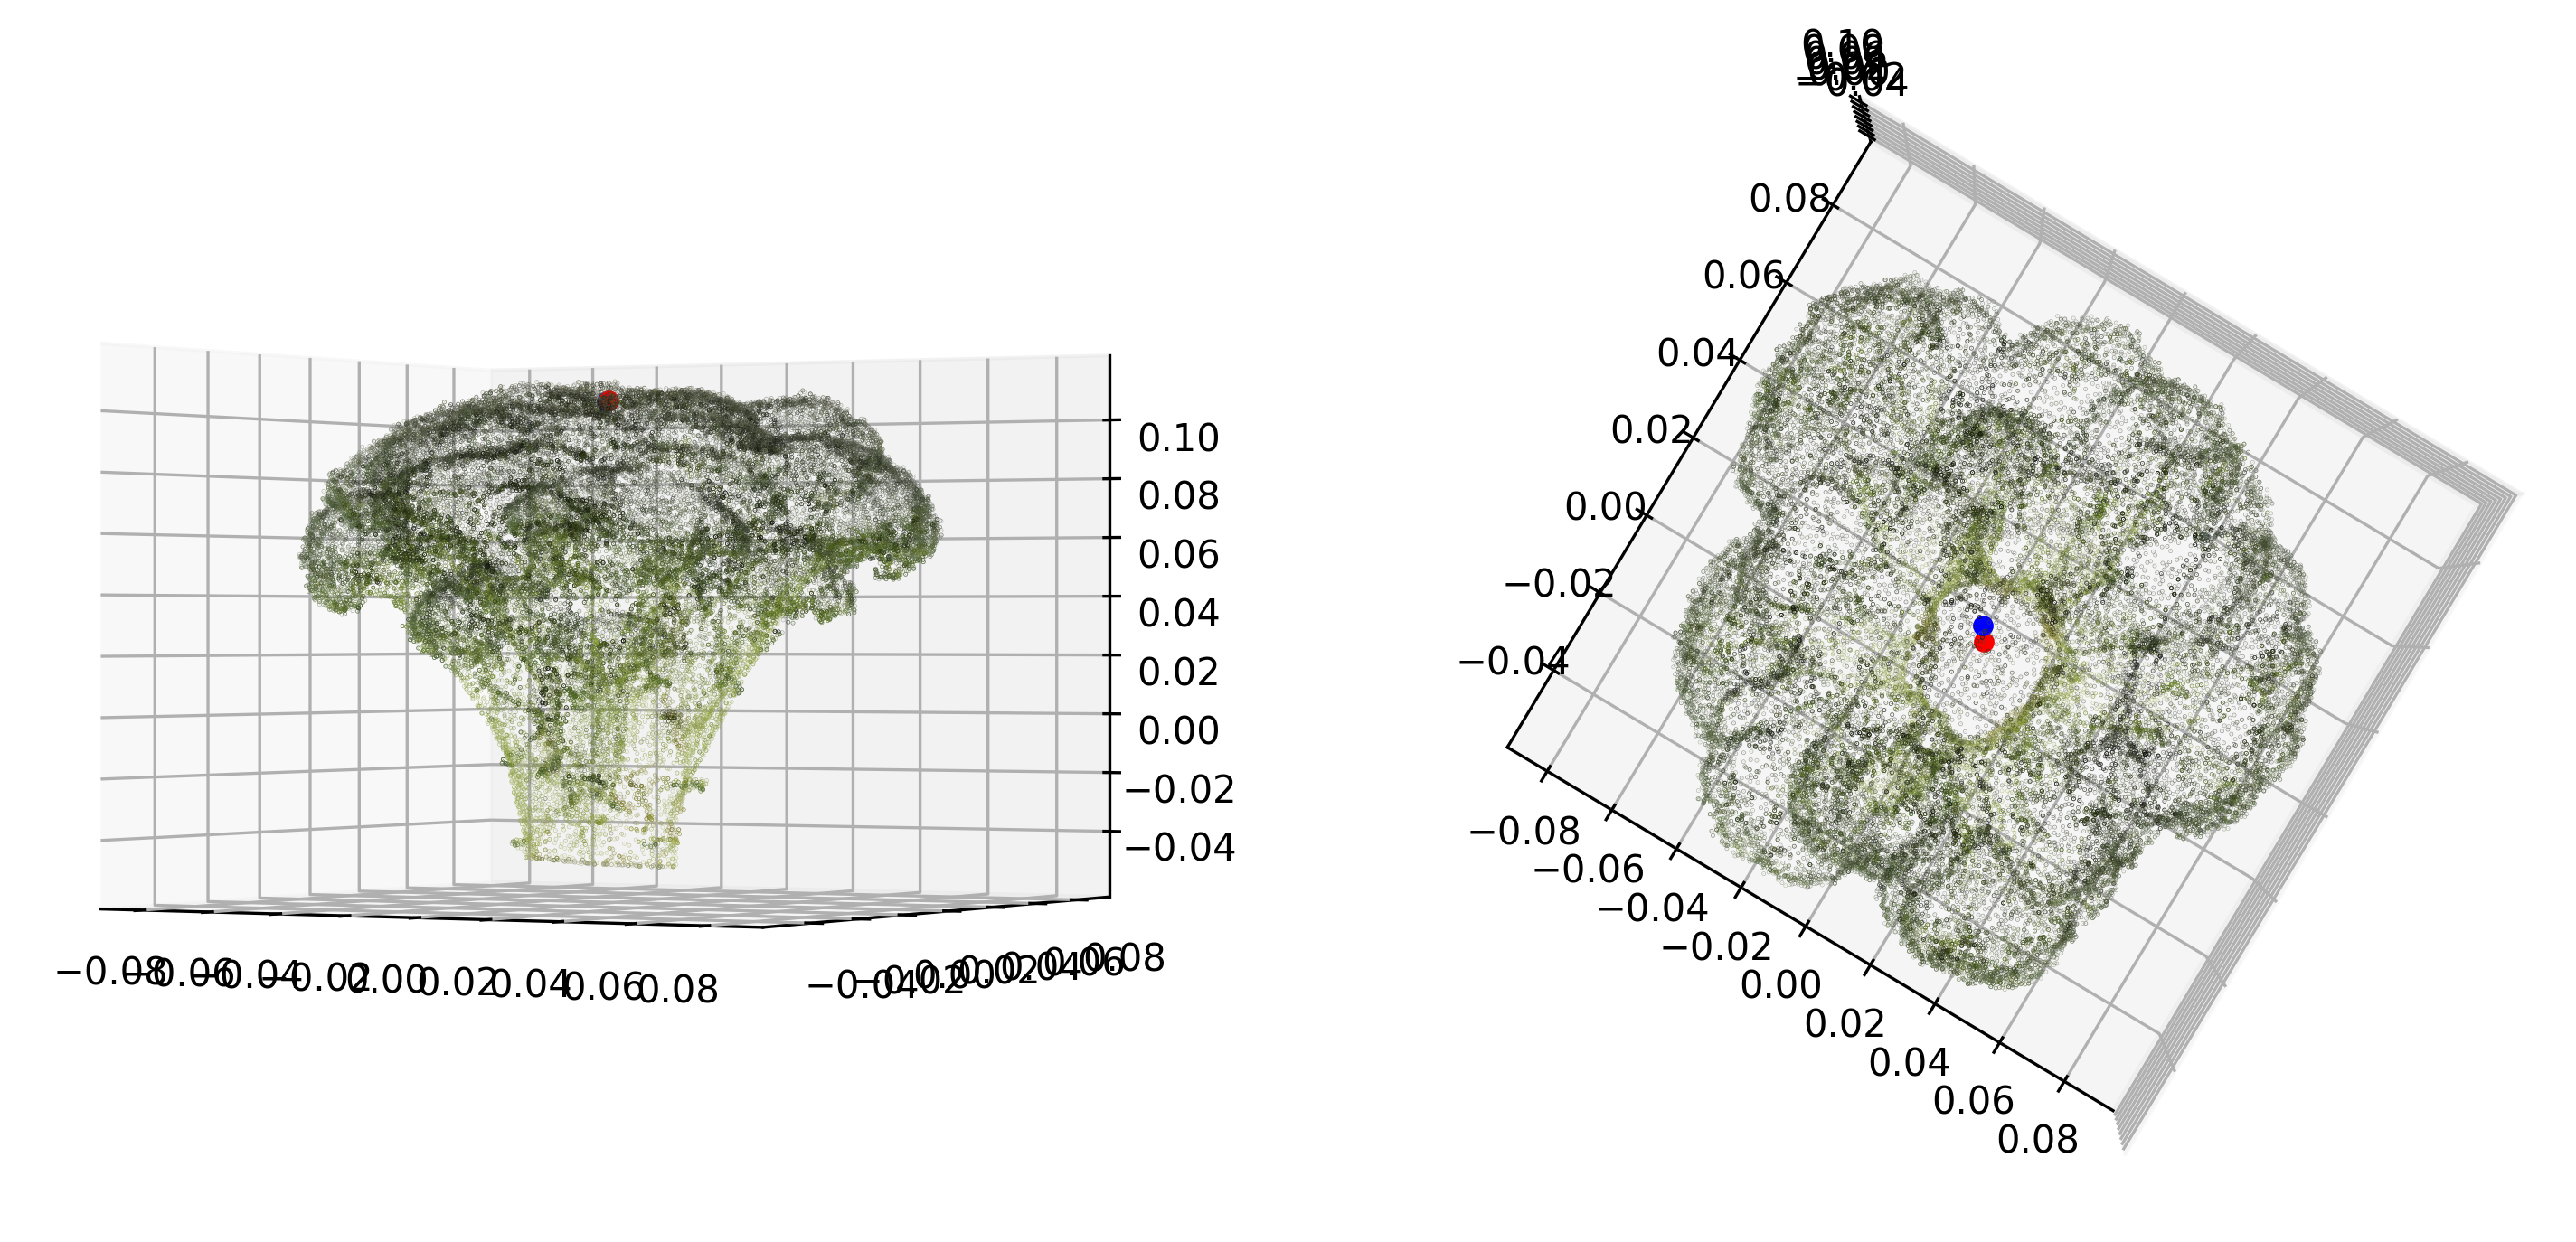

In [10]:
fig = plt.figure(figsize=(12, 6), dpi=300)
ax = fig.add_subplot(121, elev=0, projection='3d')

ax.scatter(*pts.T, color=np.array(rotated_pcd.colors), alpha=0.5, marker='.', s=0.1)

ax.scatter(*top_points.T, color='r', marker='o')
ax.scatter(xs=cx, ys=cy, zs=top_points[2], color='b', marker='o')

ax = fig.add_subplot(122, elev=90, projection='3d')

ax.scatter(*pts.T, color=np.array(rotated_pcd.colors), alpha=0.5, marker='.', s=0.1)

ax.scatter(*top_points.T, color='r', marker='o')
ax.scatter(xs=cx, ys=cy, zs=top_points[2], color='b', marker='o')

plt.show()

In [12]:
offset_pts = np.array([cx, cy, top_points[2]])
offset_pts

array([-0.01260445,  0.02925821,  0.10691689])

In [11]:
mesh_r.vertices = o3d.utility.Vector3dVector(
    np.asarray(mesh_r.vertices) - offset_pts
)

In [ ]:
o3d.visualization.draw_geometries([mesh_r, o3d_xyz_coord])

: 

: 

In [12]:
o3d.io.write_triangle_mesh(f'test_{bro_id}.obj', mesh_r)

True

In [12]:
mesh.textures

[Image of size 2048x2048, with 3 channels.
 Use numpy.asarray to access buffer data.]

In [13]:
def rotate_mesh(mesh_obj, R, center_xy, buffer=0.005):
    mesh_r = copy(mesh_obj).rotate(R)
    pts = np.asarray(mesh_obj.vertices)

    cx, cy = center_xy

    # find all points in buffer area
    range_idx = np.where(
        (pts[:,0] > cx - buffer) & (pts[:,0] < cx + buffer) & \
        (pts[:,1] > cy - buffer) & (pts[:,1] < cy + buffer))[0]
    
    # find the highest points as z value
    max_z_idx = np.argmax(pts[range_idx, 2])
    top_points = pts[range_idx[max_z_idx], :]
    
    # get the offset_xyz
    offset_pts = np.array([cx, cy, top_points[2]])

    # move the mesh to origin
    mesh_r.vertices = o3d.utility.Vector3dVector(
        np.asarray(mesh_r.vertices) - offset_pts
    )

    return mesh_r, offset_pts

In [14]:
out_mesh, offset_pts = rotate_mesh(mesh, R, crown_traits.centroid)